# Transformer AR vs causal encoder — last checkpoint, singletons and longer instructions (8 runs)

| condition | slots S | train k | held-out tests |
|---|---|---|---|
| S5_k0234 | 5 | 0,2,3,4 | k=1 at every slot; k=5 (243 words) |
| S6_k02345 | 6 | 0,2,3,4,5 | k=1; k=6 (729 words) |
| S7_k02345 | 7 | 0,2,3,4,5 | k=1; k=6 (729); k=7 (2187 words) |
| S7_k023456 | 7 | 0,2,3,4,5,6 | k=1; k=7 (2187 words) |

**Format.** Visible `<identity>` fillers, learned positions. Every longer test stays within S, so it adds no new
physical positions.

**Models.** `transformer_ar` (autoregressive, free-running) and `causal_encoder` (causal attention with 36 parallel
output queries, no feedback).

**Training.** seed 42, 5000 × 256.
* One common initialization per architecture: all conditions share positional capacity 7.
* S6_k02345 and S7_k02345 see the identical logical training stream.

**Evaluation: the LAST checkpoint, i.e. the model after update 5000.** The best checkpoint is still saved, and its
step is reported for reference.

**Test size.** 1000 test grids, except k=7, which uses `K7_GRIDS` grids (default 300, i.e. 656,100 records per run).

**Send back `LongK_AR_vs_CausalEnc_Review.ipynb`** (printed and downloaded by the last cell).


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 0fbe075b63dcf05e87834a22d50c12ad6cc8ae70


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ["S5_k0234", "S6_k02345", "S7_k02345", "S7_k023456"]
RUN_MODELS = ["transformer_ar", "causal_encoder"]
N_TEST_GRIDS = 1000
K7_GRIDS = 300                 # grids used for the 2187 k=7 words (raise to 1000 for the full set; ~3x the time)
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX
for e in RUN_CONDITIONS:
    print(e, "expected test records per model:", f"{LK.expected_records(e, N_TEST_GRIDS, K7_GRIDS):,}")
print("results ->", LX.family_root(RESULTS_ROOT, MODE))


Mounted at /content/drive
S5_k0234 expected test records per model: 376,000
S6_k02345 expected test records per model: 1,108,000
S7_k02345 expected test records per model: 1,767,100
S7_k023456 expected test records per model: 1,767,100
results -> /content/drive/MyDrive/decompositionality_results/longk_ar_vs_causal_encoder_v1


In [3]:
# --- Train + evaluate the LAST checkpoint, sequentially (resumable) --------------------------------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR),
                      n_grids=N_TEST_GRIDS, k7_grids=K7_GRIDS, device=DEVICE)
display(status)


[S5_k0234] S=5 train k=[0, 2, 3, 4] | val 1200 | manifests bdf24c327a65

=== S5_k0234 / transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,703,636 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.4297 (best) | subset(128) exact 0.242 cell 0.423
  [val @ 500] cell CE 1.0376 (best) | subset(128) exact 0.266 cell 0.477
  step 525/5000 loss 0.9628 lr 2.98e-04 | 25.87 steps/s, 6622 ex/s | ETA 2.9 min
  [val @ 750] cell CE 0.6659 (best) | subset(128) exact 0.281 cell 0.607
  [val @ 1000] cell CE 0.2979 (best) | subset(128) exact 0.383 cell 0.793
  step 1050/5000 loss 0.2293 lr 2.82e-04 | 25.52 steps/s, 6534 ex/s | ETA 2.6 min
  [val @ 1250] cell CE 0.1005 (best) | subset(128) exact 0.602 cell 0.943
  [val @ 1500] cell CE 0.0370 (best) | subset(128) exact 0.703 cell 0.979
  step 1550/5000 loss 0.0375 lr 2.53e-04 | 25.24 steps/s, 6462 ex/s | ETA 2.3 min
  [val @ 1750] cell CE 0.0205 (best)

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S5_k0234,transformer_ar,True,True,376000,4750,True
1,S5_k0234,causal_encoder,True,True,376000,5000,True
2,S6_k02345,transformer_ar,True,True,1108000,5000,True
3,S6_k02345,causal_encoder,True,True,1108000,5000,True
4,S7_k02345,transformer_ar,True,True,1767100,4500,True
5,S7_k02345,causal_encoder,True,True,1767100,5000,True
6,S7_k023456,transformer_ar,True,True,1767100,4750,True
7,S7_k023456,causal_encoder,True,True,1767100,4750,True


# Transformer AR vs causal encoder — LAST checkpoint, singletons and longer instructions (seed 42)
8/8 runs complete. Every number below is for the model after the final update (not the validation-selected checkpoint).


### Run status


,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S5_k0234,transformer_ar,True,True,376000,4750,True
1,S5_k0234,causal_encoder,True,True,376000,5000,True
2,S6_k02345,transformer_ar,True,True,1108000,5000,True
3,S6_k02345,causal_encoder,True,True,1108000,5000,True
4,S7_k02345,transformer_ar,True,True,1767100,4500,True
5,S7_k02345,causal_encoder,True,True,1767100,5000,True
6,S7_k023456,transformer_ar,True,True,1767100,4750,True
7,S7_k023456,causal_encoder,True,True,1767100,4750,True



### Summary: singletons and longer held-out instructions (LAST checkpoint)


,condition,model,status,A,B,C,singletons,singleton cell acc,trained-k exact,k=5 exact,k=6 exact,k=7 exact
0,S5_k0234,transformer_ar,available,2/5000,461/5000,0/5000,463/15000,0.6260,0.9991,0/243000 (0.000),NaN,NaN
1,S5_k0234,causal_encoder,available,3/5000,5000/5000,499/5000,5502/15000,0.9028,1.0000,72683/243000 (0.299),NaN,NaN
2,S6_k02345,transformer_ar,available,3247/6000,5988/6000,0/6000,9235/18000,0.9006,0.9969,NaN,264622/729000 (0.363),NaN
3,S6_k02345,causal_encoder,available,6000/6000,6000/6000,6000/6000,18000/18000,1.0000,1.0000,NaN,728912/729000 (1.000),NaN
4,S7_k02345,transformer_ar,available,9/7000,5697/7000,0/7000,5706/21000,0.5698,0.9873,NaN,54339/729000 (0.075),8792/656100 (0.013)
5,S7_k02345,causal_encoder,available,7000/7000,7000/7000,7000/7000,21000/21000,1.0000,0.9979,NaN,264198/729000 (0.362),3648/656100 (0.006)
6,S7_k023456,transformer_ar,available,6246/7000,6889/7000,0/7000,13135/21000,0.6952,0.9829,NaN,NaN,393247/656100 (0.599)
7,S7_k023456,causal_encoder,available,970/7000,7000/7000,2089/7000,10059/21000,0.9047,0.9962,NaN,NaN,494438/656100 (0.754)



### Exact / cell accuracy by k


... (4 outputs left out)

,condition,model,op,n,correct,identity copy,other legal transform,non-legal grid
0,S5_k0234,transformer_ar,A,5000,2,0,0,4989
1,S5_k0234,transformer_ar,B,5000,461,0,0,4539
2,S5_k0234,transformer_ar,C,5000,0,519,0,4481
3,S5_k0234,causal_encoder,A,5000,3,0,0,4997
4,S5_k0234,causal_encoder,B,5000,5000,0,0,0
5,S5_k0234,causal_encoder,C,5000,499,0,0,4501
6,S6_k02345,transformer_ar,A,6000,3247,0,0,2753
7,S6_k02345,transformer_ar,B,6000,5988,0,0,12
8,S6_k02345,transformer_ar,C,6000,0,0,0,6000
9,S6_k02345,causal_encoder,A,6000,6000,0,0,0



### AR vs causal encoder on identical test records


,condition,k,n,AR correct,causal enc correct,both,only AR,only causal enc,neither
0,S5_k0234,0,1000,1000,1000,1000,0,0,0
1,S5_k0234,1,15000,463,5502,461,2,5041,9496
2,S5_k0234,2,9000,9000,9000,9000,0,0,0
3,S5_k0234,3,27000,26993,27000,26993,0,7,0
4,S5_k0234,4,81000,80898,81000,80898,0,102,0
5,S5_k0234,5,243000,0,72683,0,0,72683,170317
6,S6_k02345,0,1000,1000,1000,1000,0,0,0
7,S6_k02345,1,18000,9235,18000,9235,0,8765,0
8,S6_k02345,2,9000,9000,9000,9000,0,0,0
9,S6_k02345,3,27000,26983,27000,26983,0,17,0



### Exact accuracy by k


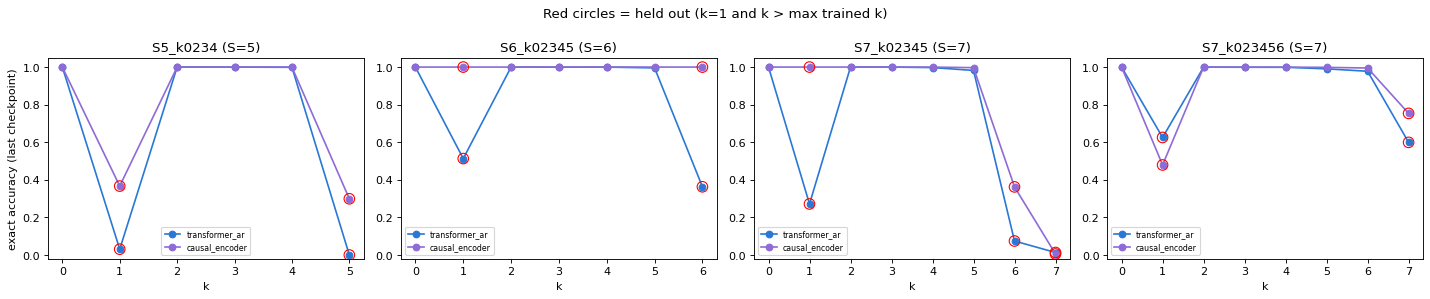

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/longk_ar_vs_causal_encoder_v1/report/seed_42/LongK_AR_vs_CausalEnc_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/longk_ar_vs_causal_encoder_v1/report/seed_42/LongK_AR_vs_CausalEnc_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Report + review export (reads saved artifacts only) -----------------------------------------------------------
rp = LX.report(RESULTS_ROOT, MODE, SEED)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))
